1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def g(x):
  x1 = x[0]
  x2 = x[1]
  return w1 * x1 + w2 * x2 + w0

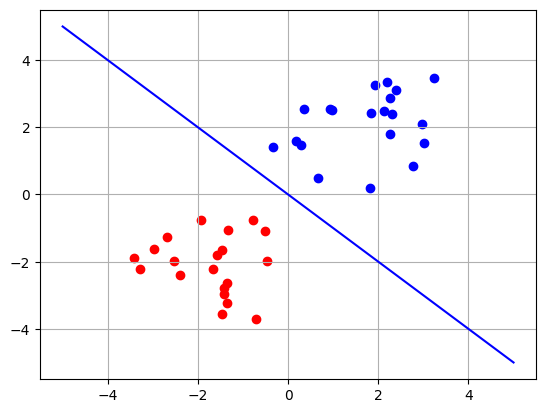

In [ ]:
x_dow = np.random.randn(20, 2) + np.array([-2, -2])
x_up = np.random.randn(20, 2) + np.array([2, 2])
plt.scatter(x_dow[:, 0], x_dow[:, 1], c='red')
plt.scatter(x_up[:, 0], x_up[:, 1], c='blue')
plt.grid(True)

w1, w2, w0 = 1, 1, 0
x1_line = np.linspace(-5, 5, 100)
x2_line = -(w1 * x1_line + w0) / w2
plt.plot(x1_line, x2_line, color='blue')

plt.show()

2

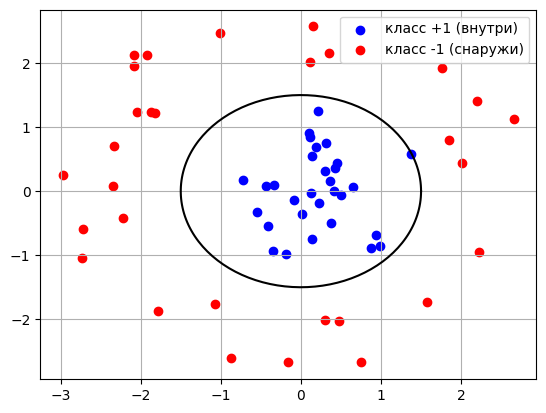

Внутренние точки
  g = -1.938
  g = -1.683
  g = -1.925
  g = -1.265
  g = -1.259
Внешние точки
  g = 3.249
  g = 3.485
  g = 6.087
  g = 2.010
  g = 5.952


In [ ]:
X_in = np.random.randn(30, 2) * 0.5

theta = np.random.uniform(0, 2 * np.pi, 30)
r     = np.random.uniform(2, 3, 30)
X_out = np.column_stack([r * np.cos(theta), r * np.sin(theta)])

a11, a12, a22 = 1, 0, 1
w1, w2, w0    = 0, 0, -2.25

def g(x):
    x1 = x[0]
    x2 = x[1]
    return a11*x1**2 + a12*x1*x2 + a22*x2**2 + w1*x1 + w2*x2 + w0

plt.scatter(X_in[:, 0],  X_in[:, 1],  c='blue',  label='класс +1 (внутри)')
plt.scatter(X_out[:, 0], X_out[:, 1], c='red',   label='класс -1 (снаружи)')

t = np.linspace(0, 2 * np.pi, 200)
R = 1.5
x1_circle = R * np.cos(t)
x2_circle = R * np.sin(t)
plt.plot(x1_circle, x2_circle, color='black')

plt.grid(True)
plt.legend()
plt.show()

print("Внутренние точки")
for x in X_in[:5]:
    print(f"  g = {g(x):.3f}")

print("Внешние точки")
for x in X_out[:5]:
    print(f"  g = {g(x):.3f}")

3

In [ ]:
from scipy.optimize import minimize
np.random.seed(0)
n = 50
x = np.linspace(-3, 3, n)
y_true = 0.5 * x**2 - x + 2
y = y_true + np.random.randn(n) * 0.8

y_class = (y > np.median(y)).astype(int)

def linear(x, params):
    w1, w0 = params
    return w1 * x + w0

def mae(params, x, y):
    y_pred = linear(x, params)
    return np.mean(np.abs(y - y_pred))

def quadratic(x, params):
    a, b, c = params
    return a * x**2 + b * x + c

def mse(params, x, y):
    y_pred = quadratic(x, params)
    return np.mean((y - y_pred)**2)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def logistic(x, params):
    w1, w0 = params
    return sigmoid(w1 * x + w0)

def log_loss(params, x, y):
    p = logistic(x, params)
    p = np.clip(p, 1e-10, 1 - 1e-10)  # чтобы не было log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def cubic(x, params):
    a, b, c, d = params
    return a * x**3 + b * x**2 + c * x + d

def rmse(params, x, y):
    y_pred = cubic(x, params)
    return np.sqrt(np.mean((y - y_pred)**2))

res_linear = minimize(mae, [1, 0], args=(x, y), method='Nelder-Mead')
res_quad = minimize(mse, [1, 1, 1], args=(x, y), method='Nelder-Mead')
res_log = minimize(log_loss, [1, 0], args=(x, y_class), method='Nelder-Mead')
res_cubic = minimize(rmse, [1, 1, 1, 1], args=(x, y), method='Nelder-Mead')

Линейная (MAE):       [-1.24679272  3.45973109]
Квадратичная (MSE):   [ 0.52049189 -1.18821764  2.04846115]
Логистическая (log):  [-1.07344596e+00  2.54678739e-05]
Кубическая (RMSE):    [-0.02464749  0.52048289 -1.04977619  2.04849271]


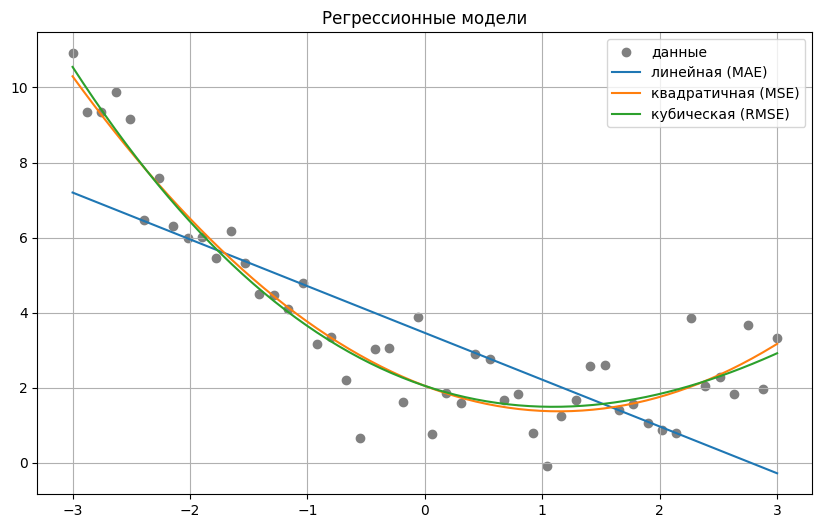

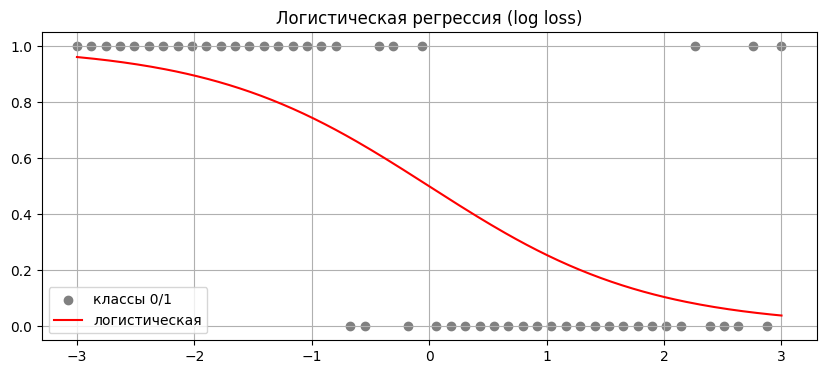

In [ ]:
res_lin  = minimize(mae,      [1, 0],       args=(x, y),       method='Nelder-Mead')
res_quad = minimize(mse,      [1, 1, 1],    args=(x, y),       method='Nelder-Mead')
res_log  = minimize(log_loss, [1, 0],       args=(x, y_class), method='Nelder-Mead')
res_cub  = minimize(rmse,     [1, 1, 1, 1], args=(x, y),       method='Nelder-Mead')

print("Линейная (MAE):      ", res_lin.x)
print("Квадратичная (MSE):  ", res_quad.x)
print("Логистическая (log): ", res_log.x)
print("Кубическая (RMSE):   ", res_cub.x)


plt.figure(figsize=(10, 6))
plt.scatter(x, y, c='gray', label='данные')

x_plot = np.linspace(-3, 3, 200)
plt.plot(x_plot, linear(x_plot, res_lin.x),  label='линейная (MAE)')
plt.plot(x_plot, quadratic(x_plot, res_quad.x), label='квадратичная (MSE)')
plt.plot(x_plot, cubic(x_plot, res_cub.x),   label='кубическая (RMSE)')

plt.legend()
plt.grid(True)
plt.title('Регрессионные модели')
plt.show()

plt.figure(figsize=(10, 4))
plt.scatter(x, y_class, c='gray', label='классы 0/1')
plt.plot(x_plot, logistic(x_plot, res_log.x), c='red', label='логистическая')
plt.legend()
plt.grid(True)
plt.title('Логистическая регрессия (log loss)')
plt.show()

4


Мы ищем такие параметры линейной модели, при которых средний квадрат ошибки (MSE) минимален.

MSE — это функция от параметров. Она измеряет, насколько предсказания модели далеки от истинных ответов. Чем меньше значение — тем лучше модель.

Эта функция — квадратичная и выпуклая. Если нарисовать её график, получится «чаша» с единственной самой низкой точкой. Других локальных минимумов нет.

Чтобы найти дно чаши, нужно взять производную функции по параметрам и приравнять её к нулю. В этой точке наклон графика нулевой — значит, мы на дне.

После взятия производной и приравнивания к нулю получается система линейных уравнений относительно параметров. Она называется нормальными уравнениями.

Решая эту систему, получаем искомую формулу для оптимальных параметров через матрицы признаков и ответов.

Поскольку функция выпуклая, найденная точка — гарантированно глобальный минимум, а не локальный. Других минимумов у неё нет.

Вывод: формула даёт именно те параметры, при которых MSE минимален, потому что она получена из условия равенства нулю производной выпуклой функции.

5

In [ ]:
logits = np.array([2.0, 1.0, 0.1, 3.5, 0.5])

def softmax(logits, tau=1.0):
    z = logits / tau                    # температура
    z = z - np.max(z)                   # защита от переполнения
    e = np.exp(z)
    return e / np.sum(e)

probs = softmax(logits)
print("Вероятности:", probs)
print("Сумма:", probs.sum())

best_class = np.argmax(probs)
print("Класс с макс. вероятностью:", best_class)
print("Его вероятность:", probs[best_class])

def entropy(probs):
    # защита от log(0)
    p = probs[probs > 0]
    return -np.sum(p * np.log(p))

H = entropy(probs)
print("Энтропия (наты):", H)
print("Максимум для", len(logits), "классов:", np.log(len(logits)))

Вероятности: [0.16071312 0.05912305 0.02403764 0.72026624 0.03585994]
Сумма: 1.0
Класс с макс. вероятностью: 3
Его вероятность: 0.7202662407168655
Энтропия (наты): 0.9063194811272027
Максимум для 5 классов: 1.6094379124341003
